### In this notebook I tried a different approach with combining the datasets and did some EDA with the whole set

In [2]:
# IMPORTS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score

In [3]:
# Combining the datasets together with a new column for run_id and road_id

dfA1 = pd.read_csv("../dataset/cleaned/Iisingintie0.csv")
dfA2 = pd.read_csv("../dataset/cleaned/Iisingintie1.csv")
dfA3 = pd.read_csv("../dataset/cleaned/Iisingintie2.csv")

dfB1 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie0.csv")
dfB2 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie1.csv")
dfB3 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie2.csv")
dfB4 = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")

dfC1 = pd.read_csv("../dataset/cleaned/Kaittiaisentie1.csv")


runs = {
    "A1": (dfA1, "A"), "A2": (dfA2, "A"), "A3": (dfA3, "A"),
    "B1": (dfB1, "B"), "B2": (dfB2, "B"), "B3": (dfB3, "B"), "B4": (dfB4, "B"),
    "C1": (dfC1, "C"),
}

df = pd.concat(
    [d.assign(run_id=rid, road_id=road) for rid, (d, road) in runs.items()],
    ignore_index=True,
)

In [4]:
len(df)

415760

In [5]:
run_names = list(runs.keys())
print(run_names)

['A1', 'A2', 'A3', 'B1', 'B2', 'B3', 'B4', 'C1']


In [6]:
df

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps,run_id,road_id
0,45493158.5,3850.503,106.794,1.1747,-3.0780,141.0204,1.53481,0.05712,9.58495,0.03196,0.00072,-0.00300,62.1936,0,A1,A
1,45493161.0,3850.546,106.794,1.2245,-3.0428,141.1350,1.51066,-0.04196,10.50449,0.02201,0.00598,-0.01390,62.2044,0,A1,A
2,45493163.5,3850.589,106.794,1.2281,-3.0428,141.1349,1.15831,0.37071,10.76888,0.01993,0.00065,-0.00562,62.2116,0,A1,A
3,45493166.0,3850.633,106.794,1.2330,-3.0430,141.1341,1.03301,0.31102,11.42271,0.02887,-0.00077,-0.01012,62.2224,0,A1,A
4,45493168.5,3850.676,106.794,1.2363,-3.0431,141.1329,0.99574,-0.37334,11.76243,0.01783,0.00007,-0.01306,62.2332,0,A1,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
415755,48394974.5,3177.920,120.720,-0.9675,-3.4588,-47.2120,-0.68158,0.08021,9.89489,-0.02289,-0.00231,0.00294,14.8608,0,C1,C
415756,48394977.0,3177.920,120.720,-0.9701,-3.4581,-47.2115,-0.70976,0.04869,9.84995,-0.02335,0.00517,-0.00078,14.8464,0,C1,C
415757,48394979.5,3177.920,120.720,-0.9719,-3.4568,-47.2122,-0.77364,0.00735,9.95328,-0.01821,0.01022,-0.00917,14.8356,0,C1,C
415758,48394982.0,3177.920,120.720,-0.9744,-3.4563,-47.2120,-0.78316,0.02913,9.89511,-0.02315,0.00434,-0.00332,14.8212,0,C1,C


In [7]:
feature_cols = ["AccX", "AccY", "AccZ", "GyrX", "GyrY", "GyrZ",
                "Pitch(deg)", "Roll(deg)", "Speed_kmh"]


In [8]:
# This code makes row windows of the data, with a given window size and stride. It returns the X and y values for each window.

# def make_row_windows(run_df, win=100, stride=20):
#     run_df = run_df.sort_values("Timer(ms)")
#     X = run_df[feature_cols].to_numpy(np.float32)
#     y = run_df["Frostbumps"].to_numpy()

#     X_clips, y_clips = [], []
#     for start in range(0, len(X) - win + 1, stride):
#         end = start + win
#         X_clips.append(X[start:end])
#         y_clips.append(y[start:end].max())

#     return np.array(X_clips), np.array(y_clips)

In [9]:
def make_row_windows(run_df, win=0, stride=0, min_percentage=0.1):
    run_df = run_df.sort_values("Timer(ms)")

    X = run_df[feature_cols].to_numpy(np.float32)
    y = run_df["Frostbumps"].to_numpy()

    X_clips, y_clips = [], []

    for start in range(0, len(X) - win + 1, stride):
        end = start + win

        X_clips.append(X[start:end])

        bump_percentage = y[start:end].mean()
        y_clips.append(int(bump_percentage >= min_percentage))

    return np.array(X_clips), np.array(y_clips)

In [10]:
def get_clips(run_names):
    all_X, all_y = [], []
    for name in run_names:
        one_run = df[df["run_id"] == name]
        X, y = make_row_windows(one_run, win=600, stride=400)
        all_X.append(X)
        all_y.append(y)
    return np.concatenate(all_X), np.concatenate(all_y)

In [11]:
# Checking the number of windows per run

for run in ["A1", "A2", "A3", "B1", "B3", "B4", "C1"]:
    X, y = get_clips([run])

    print(
        f"{run}: {len(y)} windows, "
        f"{y.mean():.1%} positive"
    )

A1: 141 windows, 30.5% positive
A2: 188 windows, 26.6% positive
A3: 286 windows, 22.4% positive
B1: 23 windows, 43.5% positive
B3: 32 windows, 37.5% positive
B4: 44 windows, 38.6% positive
C1: 286 windows, 7.7% positive


In [12]:
# Training, validation, test splits

Xtr, ytr = get_clips(["A2", "B1", "B3", "A3"])
Xva, yva = get_clips(["B4", "A1"])
Xte, yte = get_clips(["C1"])

print(Xtr.shape, Xva.shape, Xte.shape)
print(ytr.mean(), yva.mean(), yte.mean())

(529, 600, 9) (185, 600, 9) (286, 600, 9)
0.2570888468809074 0.32432432432432434 0.07692307692307693


In [28]:
for run in sorted(df["run_id"].unique()):
    run_df = df[df["run_id"] == run]

    print(
        run,
        "Rows:", len(run_df),
        "Start:", run_df["Timer(ms)"].min(),
        "End:", run_df["Timer(ms)"].max()
    )

A1 Rows: 56873 Start: 45493158.5 End: 45635338.5
A2 Rows: 75465 Start: 45913936.5 End: 46102597.4
A3 Rows: 114684 Start: 46346098.5 End: 46632806.0
B1 Rows: 9599 Start: 41145884.1 End: 41169879.0
B2 Rows: 12985 Start: 41279124.1 End: 41311834.0
B3 Rows: 13083 Start: 41402111.1 End: 41434816.0
B4 Rows: 18128 Start: 41518221.1 End: 41563788.5
C1 Rows: 114943 Start: 48108949.6 End: 48396304.5


In [33]:
print(df.groupby("road_id")[feature_cols].mean().T)

road_id             A          B          C
AccX         0.514394   0.209464   0.482411
AccY         0.328778   0.130762   0.055764
AccZ         9.816107   9.841346   9.819258
GyrX        -0.004915  -0.005625  -0.005543
GyrY         0.001008   0.000510   0.000405
GyrZ        -0.002868  -0.005011  -0.003112
Pitch(deg)  -2.897970  -1.897171  -2.774331
Roll(deg)    1.750745  -0.684322   0.191805
Speed_kmh   53.839395  47.608150  39.742564


In [32]:
print(df.groupby("road_id")[feature_cols].std().T)

road_id             A          B         C
AccX         0.599047   1.044298  0.520416
AccY         0.556965   0.418324  0.498846
AccZ         1.194532   1.112117  0.785865
GyrX         0.036716   0.034550  0.030554
GyrY         0.049027   0.052969  0.054647
GyrZ         0.012287   0.008567  0.022192
Pitch(deg)   0.997085   7.460869  1.337173
Roll(deg)    0.812936   7.059263  1.618875
Speed_kmh   15.716943  18.241697  6.750607


In [34]:
feature_cols_no_speed = [
    col for col in feature_cols if col != "Speed_kmh"
]

In [ ]:
feature_cols_no_orientation = [
    col for col in feature_cols
    if col not in ["Pitch(deg)", "Roll(deg)"]
]

In [31]:
print(feature_cols)

['AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Pitch(deg)', 'Roll(deg)', 'Speed_kmh']


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

n_features = Xtr.shape[2]

Xtr_scaled = scaler.fit_transform(
    Xtr.reshape(-1, n_features)
).reshape(Xtr.shape)

Xva_scaled = scaler.transform(
    Xva.reshape(-1, n_features)
).reshape(Xva.shape)

Xte_scaled = scaler.transform(
    Xte.reshape(-1, n_features)
).reshape(Xte.shape)

In [14]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=Xtr.shape[1:]),
    layers.Conv1D(16, 7, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(32, 5, padding="same", activation="relu"),
    layers.GlobalMaxPooling1D(),
    layers.Dropout(0.3),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

optimizer = keras.optimizers.Adam(learning_rate=0.001)

model.compile(optimizer="adam", loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc")])

w = min((ytr == 0).sum() / max((ytr == 1).sum(), 1), 20)

history = model.fit(Xtr, ytr, validation_data=(Xva, yva),
          epochs=100, batch_size=32,
          class_weight={0: 1.0, 1: float(w)},
          callbacks=[keras.callbacks.EarlyStopping(
              monitor="val_loss", patience=10, restore_best_weights=True)])



Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 1.0911 - pr_auc: 0.4135 - val_loss: 1.0190 - val_pr_auc: 0.5099
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9512 - pr_auc: 0.5091 - val_loss: 0.8557 - val_pr_auc: 0.6122
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.9088 - pr_auc: 0.5550 - val_loss: 0.7545 - val_pr_auc: 0.6907
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8843 - pr_auc: 0.6283 - val_loss: 0.7079 - val_pr_auc: 0.6941
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8025 - pr_auc: 0.6745 - val_loss: 0.5944 - val_pr_auc: 0.6967
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7612 - pr_auc: 0.7055 - val_loss: 0.5544 - val_pr_auc: 0.7297
Epoch 7/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7536 - pr_auc: 0.7277 - val_loss: 0.5189 - val_pr_auc: 0.7458
Epoch 8/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7147 - pr_auc: 0.7416 - val_loss: 0.4842 - val_pr_auc: 0.7574
Epoch 9/100
17/

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 600, 16)        │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 300, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 300, 32)        │         2,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 32)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,485 (48.77 KB)

 Trainable params: 4,161 (16.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,324 (32.52 KB)

In [16]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Get predicted probabilities
y_pred_proba = model.predict(Xte).ravel()

# Calculate AUC scores
pr_auc = average_precision_score(yte, y_pred_proba)
roc_auc = roc_auc_score(yte, y_pred_proba)

print(f"PR-AUC:  {pr_auc:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
PR-AUC:  0.7277
ROC-AUC: 0.9144


<Axes: >

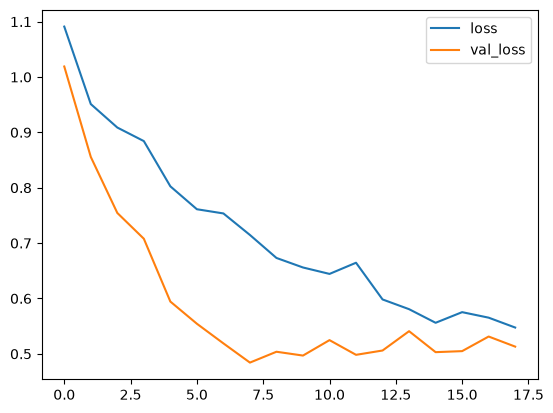

In [17]:
loss_df = pd.DataFrame(model.history.history)
loss_df[['loss', 'val_loss']].plot()

In [18]:
# compare the final model loss/accuracy/evaluation values
# the values should match mostly
print("Test data evaluation:")
print(model.evaluate(Xte, yte, verbose=0))
print("\nTrain data evaluation:")
print(model.evaluate(Xtr, ytr, verbose=0))

Test data evaluation:
[0.5801724791526794, 0.7247004508972168]

Train data evaluation:


[0.446568101644516, 0.8265262842178345]


In [19]:
test_predictions = model.predict(Xte).ravel()

test_predictions = (test_predictions >= 0.5).astype(int)


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


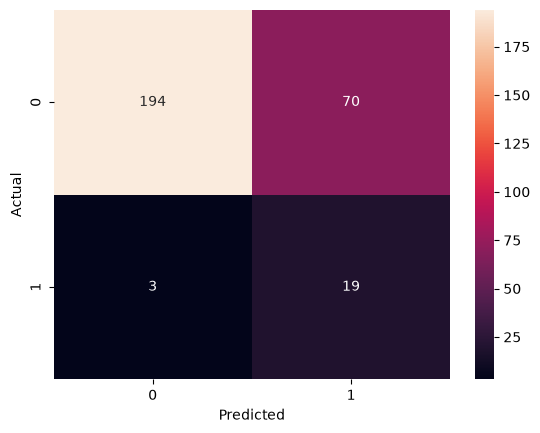

In [20]:


# confusion matrix
import seaborn as sns
sns.heatmap(confusion_matrix(yte, test_predictions), annot=True, fmt='g')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()



In [21]:
from sklearn.metrics import confusion_matrix, classification_report

y_pred = (model.predict(Xte).ravel() >= 0.6).astype(int)

print(confusion_matrix(yte, y_pred))
print(classification_report(yte, y_pred))

acc = accuracy_score(yte, test_predictions)
print("\nModel overall accuracy: {:.2f}%".format(acc * 100))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
[[221  43]
 [  5  17]]
              precision    recall  f1-score   support

           0       0.98      0.84      0.90       264
           1       0.28      0.77      0.41        22

    accuracy                           0.83       286
   macro avg       0.63      0.80      0.66       286
weighted avg       0.92      0.83      0.86       286


Model overall accuracy: 74.48%


In [22]:
y_prob = model.predict(Xte).ravel()

print("Minimum:", y_prob.min())
print("Maximum:", y_prob.max())
print("Mean:", y_prob.mean())

y_pred = (y_prob >= 0.5).astype(int)

print("Predicted classes:")
print(np.unique(y_pred, return_counts=True))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Minimum: 0.06618793
Maximum: 0.9999899
Mean: 0.45407778
Predicted classes:
(array([0, 1]), array([197,  89]))


In [23]:
y_prob = model.predict(Xte).ravel()

print("Actual frost bumps:", np.sum(yte == 1))
print("Predicted frost bumps:", np.sum(y_prob >= 0.5))

print("\nProbabilities for actual frost bumps:")
print(y_prob[yte == 1])

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Actual frost bumps: 22
Predicted frost bumps: 89

Probabilities for actual frost bumps:
[0.7404424  0.9954329  0.60160553 0.44263315 0.9574836  0.9541829
 0.57555616 0.7434241  0.5509336  0.98449934 0.98307246 0.8566841
 0.9364027  0.9515737  0.43249682 0.9398076  0.9792588  0.795153
 0.9529059  0.9999899  0.92365134 0.44967332]


In [24]:
# runs = ["A1", "A2", "A3", "B1", "B2", "B3", "B4"]

# test_run = "A1"
# val_run = "A2"
# train_runs = [r for r in runs if r not in (test_run, val_run)]

# print(train_runs)

In [25]:
# def build_model(input_shape):
#     model = keras.Sequential([
#         layers.Input(shape=input_shape),
#         layers.Conv1D(8, 7, padding="same", activation="relu"),
#         layers.MaxPooling1D(2),
#         layers.Conv1D(16, 5, padding="same", activation="relu"),
#         layers.GlobalMaxPooling1D(),
#         layers.Dropout(0.3),
#         layers.Dense(16, activation="relu"),
#         layers.Dense(1, activation="sigmoid"),
#     ])
#     model.compile(optimizer="adam", loss="binary_crossentropy")
#     return model

In [26]:
# scores = {}

# for i, test_run in enumerate(runs):
#     val_run = runs[(i + 1) % len(runs)]
#     train_runs = [r for r in runs if r not in (test_run, val_run)]

#     Xtr, ytr = get_clips(train_runs)
#     Xva, yva = get_clips([val_run])
#     Xte, yte = get_clips([test_run])

#     n_features = Xtr.shape[-1]
#     scaler = StandardScaler().fit(Xtr.reshape(-1, n_features))
#     Xtr = scaler.transform(Xtr.reshape(-1, n_features)).reshape(Xtr.shape)
#     Xva = scaler.transform(Xva.reshape(-1, n_features)).reshape(Xva.shape)
#     Xte = scaler.transform(Xte.reshape(-1, n_features)).reshape(Xte.shape)

#     keras.backend.clear_session()
#     model = build_model(Xtr.shape[1:])

#     model.fit(
#         Xtr, ytr,
#         validation_data=(Xva, yva),
#         epochs=30,
#         batch_size=32,
#         class_weight={0: 1.0, 1: 3.0},
#         verbose=0,
#         callbacks=[keras.callbacks.EarlyStopping(
#             monitor="val_loss", patience=5, restore_best_weights=True)],
#     )

#     probs = model.predict(Xte, verbose=0).ravel()
#     scores[test_run] = average_precision_score(yte, probs)
#     print(test_run, "score:", round(scores[test_run], 2),
#           "| random guess:", round(yte.mean(), 2))

# print("mean:", sum(scores.values()) / len(scores))